[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/01_EDA_and_preprocessing.ipynb)

# 01. Dataset exploration and preprocessing
**Run on:** Laptop A · **Approx. runtime:** ~4 min on a 4-core laptop

Inventory of the raw files, data-quality checks, GPS and network plots, an interactive Folium map, then building the candidate/feature tables used by every model notebook.

**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


## 1. Exploratory data analysis
Runs `scripts/00_eda.py`, which reads every trip in **train** and **student_test**, checks missing values, timestamps, coordinates and network connectivity, and saves tables and plots to `results/01_eda_preprocessing/`.

In [2]:
sys.path.insert(0, os.path.join(ROOT, "scripts"))
from importlib import import_module
import_module("00_eda").main()

train 00000001


train 00000002


train 00000003


train 00000004


train 00000005


train 00000006


... (83 outputs left out)

student_test 00000076


student_test 00000077


student_test 00000091


== student_test: 10 trips
        points  duration_s  path_km  dt_max  frac_dt_1s  gaps_over_10s  route_arcs  route_km
count    10.00       10.00    10.00   10.00       10.00          10.00       10.00     10.00
mean   1916.00     2025.00    29.70   25.50        0.98           2.70      347.70     24.77
std    1335.43     1311.67    22.84   65.53        0.04           7.54      359.57     21.23
min     262.00      265.00     5.55    1.00        0.86           0.00       95.00      5.28
25%     917.75     1040.00    12.17    1.00        0.99           0.00      153.50      9.86
50%    1420.00     1809.50    20.94    2.00        1.00           0.00      250.00     14.73
75%    2872.00     2871.25    48.41    2.75        1.00           0.00      357.75     40.19
max    3958.00     4000.00    71.72  210.00        1.00          24.00     1323.00     64.76
           nodes      arcs  isolated_nodes  weak_components  strong_components  largest_strong_frac  two_way_frac
count     10.000     10

In [3]:
inv = pd.read_csv("results/01_eda_preprocessing/inventory.csv", dtype={"trip": str})
net = pd.read_csv("results/01_eda_preprocessing/network.csv", dtype={"trip": str})
print("Missing-value / validity checks per partition:")
display(inv.groupby("split")[["track_nan", "non_monotonic_ts", "coords_out_of_range", "gaps_over_10s"]].sum())
display(inv.groupby("split")[["points", "duration_s", "path_km", "dt_max", "frac_dt_1s", "route_arcs"]].describe().round(2))

Missing-value / validity checks per partition:


,track_nan,non_monotonic_ts,coords_out_of_range,gaps_over_10s
split,,,,
student_test,0,0,0,27
train,0,0,0,590


points                                                            duration_s          ... frac_dt_1s      route_arcs                       \
              count     mean      std    min     25%     50%      75%      max      count    mean  ...        75%  max      count   mean     std   min   
split                                                                                              ...                                                   
student_test   10.0  1916.00  1335.43  262.0  917.75  1420.0  2872.00   3958.0       10.0  2025.0  ...        1.0  1.0       10.0  347.7  359.57  95.0   
train          80.0  2605.21  3312.35  361.0  945.75  1529.0  2792.75  19313.0       80.0  5680.4  ...        1.0  1.0       80.0  391.7  361.17  59.0   

                                             
                 25%    50%     75%     max  
split                                        
student_test  153.50  250.0  357.75  1323.0  
train         168.25  280.0  480.50  2266.0  

[2 rows x 48 columns]

In [4]:
display(net.groupby("split")[["nodes", "arcs", "isolated_nodes", "weak_components", "strong_components",
                               "largest_strong_frac", "two_way_frac"]].describe().round(3))

nodes                                                                     arcs           ... largest_strong_frac        two_way_frac         \
             count       mean        std     min      25%     50%       75%       max count     mean  ...                 75%    max        count   mean   
split                                                                                                 ...                                                  
student_test  10.0   9068.900   7452.176  1770.0  4908.00  6596.5  11844.25   26635.0  10.0  18504.1  ...               0.972  0.984         10.0  0.927   
train         80.0  24168.562  32272.296   299.0  3487.75  9608.0  28846.75  155003.0  80.0  48461.3  ...               0.982  1.000         80.0  0.922   

                                                        
                std    min    25%    50%    75%    max  
split                                                   
student_test  0.057  0.855  0.875  0.933  0.976  0.996  
train         0.095  0.351  0.898  0.951  0.984  1.000  

[2 rows x 56 columns]

## 2. Plots

sampling_and_length


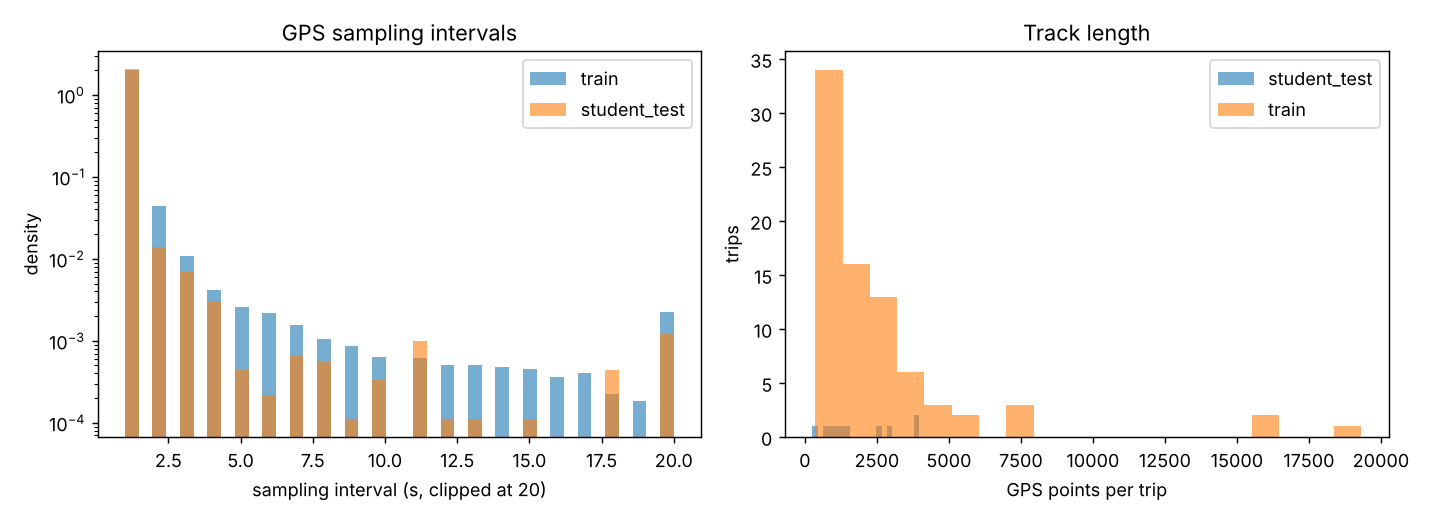

gps_to_road_distance


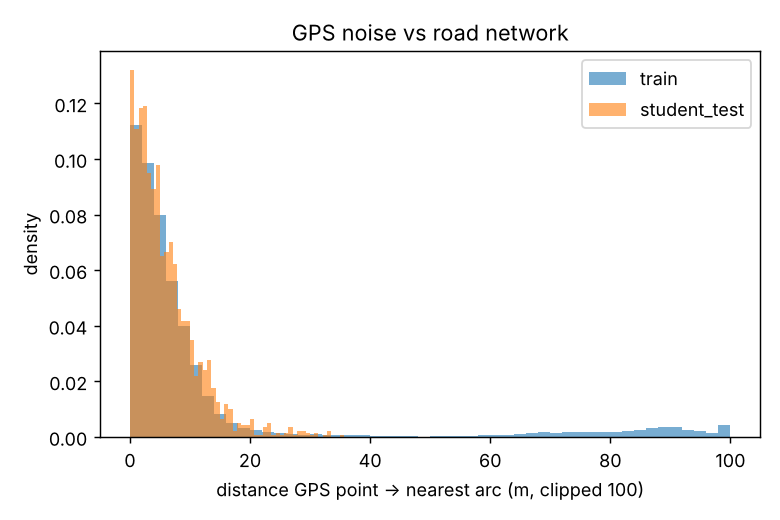

trip_locations


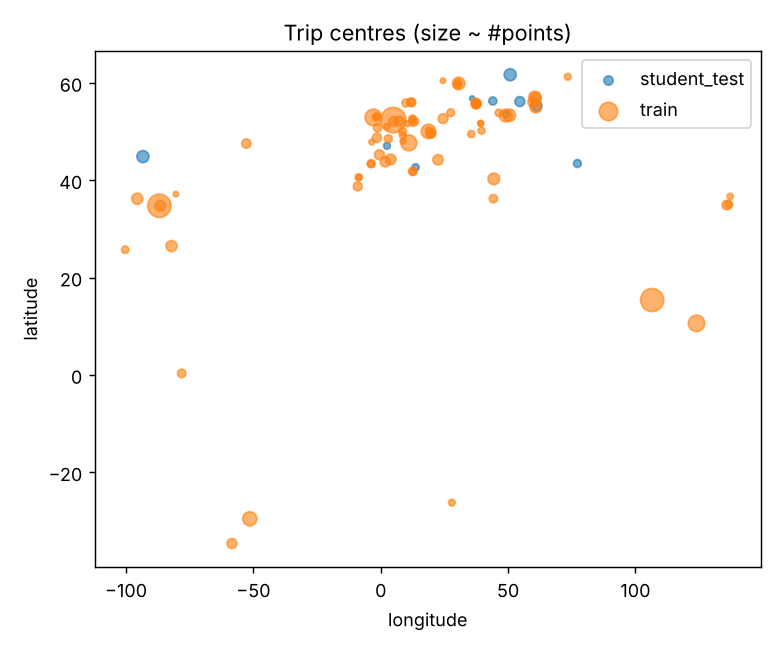

network_size


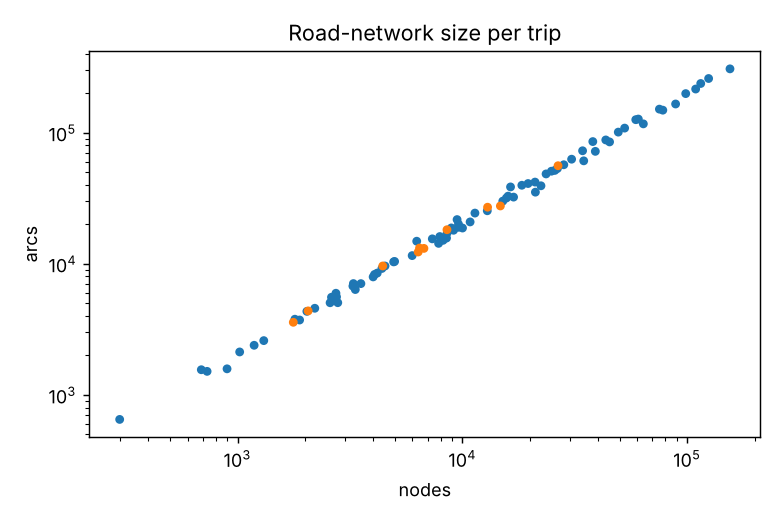

example_trip


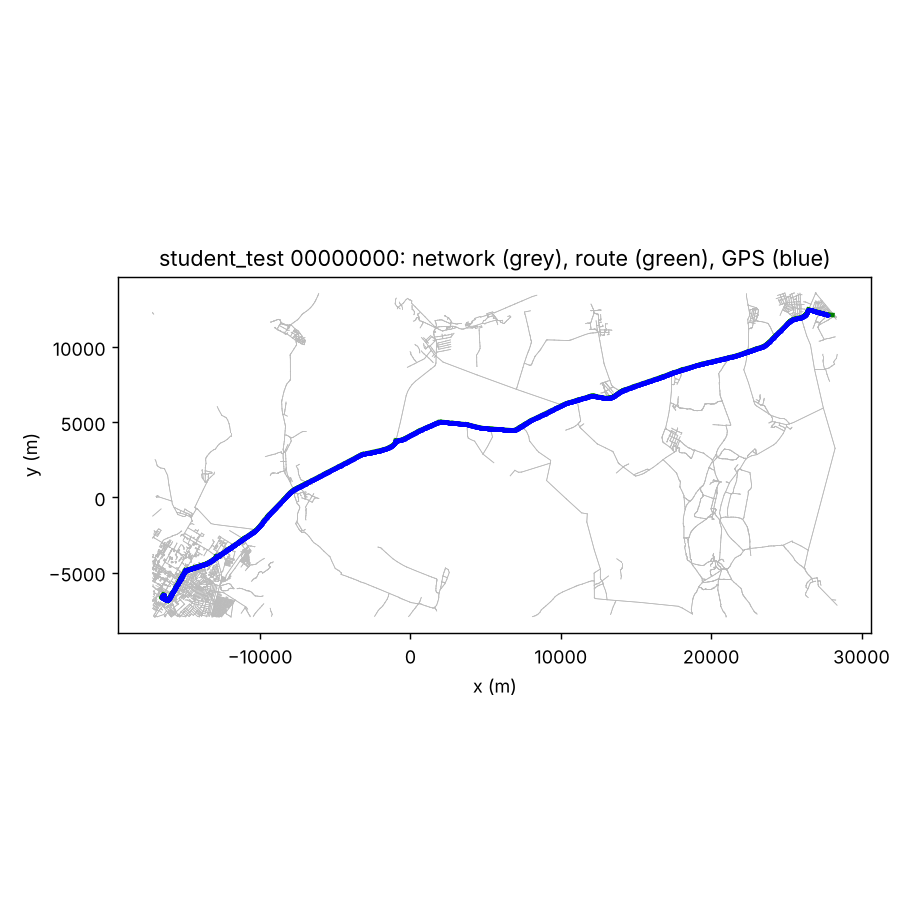

In [5]:
from IPython.display import Image, display
for f in ["sampling_and_length", "gps_to_road_distance", "trip_locations", "network_size", "example_trip"]:
    print(f); display(Image(f"results/01_eda_preprocessing/{f}.png"))

## 3. Interactive Folium map (student_test trip 00000000)
GPS observations, the road network near the track, and the reference route. Use the layer control (top right).

In [6]:
from pathsnap.data import load_trip
from pathsnap.viz import trip_map
trip = load_trip("data/student_test", "00000000")
m = trip_map(trip, [("Reference route", trip.route, "#1a9e3a", 7, None)], "student_test 00000000 (EDA)")
m

## 4. Labels and candidates
`.route` lists the arcs driven but not which GPS point belongs to which arc. `pathsnap/labels.py` aligns them with a monotonic dynamic program. Then `pathsnap/candidates.py` lists arcs within 50 m (max 8) per point, and `pathsnap/features.py` computes 14 features per (point, candidate).

In [7]:
nb.ensure_features()
for s in ["train", "student_test"]:
    l = pd.read_csv(f"results/01_eda_preprocessing/labelling_{s}.csv", dtype={"trip": str})
    print(f"{s}: labelled {(l.labelled_frac * l.points).sum() / l.points.sum():.4f}, "
          f"mean candidate miss rate {l.candidate_miss_rate.mean():.4f}")
    display(l.sort_values("labelled_frac").head(3).round(4))

feature tables found in artifacts/
train: labelled 0.8928, mean candidate miss rate 0.0150


,trip,points,labelled_frac,no_candidates_frac,candidate_miss_rate,rows,seconds
44,00000054,19313,0.1171,0.8553,0.2088,19472,1.55
26,00000033,5844,0.4762,0.0077,0.3105,32732,0.44
1,00000002,7243,0.8833,0.0704,0.0070,46330,0.58


student_test: labelled 0.9987, mean candidate miss rate 0.0037


,trip,points,labelled_frac,no_candidates_frac,candidate_miss_rate,rows,seconds
5,00000056,3958,0.9937,0.0,0.0010,26627,0.63
0,00000000,2503,1.0000,0.0,0.0020,9904,0.24
2,00000009,1049,1.0000,0.0,0.0219,7925,0.13


In [8]:
tr, tr_pts, te, te_pts = nb.load_data()
from pathsnap.features import FEATURES
print("features:", FEATURES)
display(tr[FEATURES + ["label"]].describe().T.round(3))
near = te[te.dist_rank == 0][["trip", "point", "arc"]]
m = te_pts[te_pts.true_arc >= 0].merge(near, on=["trip", "point"], how="left")
print(f"Nearest-arc baseline Top-1 on student test: {(m.arc == m.true_arc).mean():.4f}")

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows
features: ['dist', 'dist_rank', 'dist_minus_min', 'win_dist', 'heading_diff', 'heading_valid', 'speed', 'dt_prev', 'arc_len', 'proj_t', 'n_cands', 'out_deg_end', 'in_deg_start', 'has_twin']


,count,mean,std,min,25%,50%,75%,max
dist,1028261.0,17.257,13.214,0.000,6.165,13.935,26.345,50.000
dist_rank,1028261.0,2.883,2.237,0.000,1.000,3.000,5.000,7.000
dist_minus_min,1028261.0,11.844,12.961,0.000,0.000,7.543,20.362,49.894
win_dist,1028261.0,20.596,14.350,0.154,8.665,17.604,29.904,392.481
heading_diff,1028261.0,86.677,68.694,0.000,12.536,86.841,164.101,180.000
heading_valid,1028261.0,0.980,0.139,0.000,1.000,1.000,1.000,1.000
speed,1028261.0,13.822,9.799,0.000,6.853,11.525,18.349,180.185
dt_prev,1028261.0,2.425,427.048,1.000,1.000,1.000,1.000,153064.000
arc_len,1028261.0,117.897,235.697,0.070,22.537,52.084,117.093,4667.677
proj_t,1028261.0,0.497,0.419,0.000,0.000,0.493,1.000,1.000


Nearest-arc baseline Top-1 on student test: 0.5418


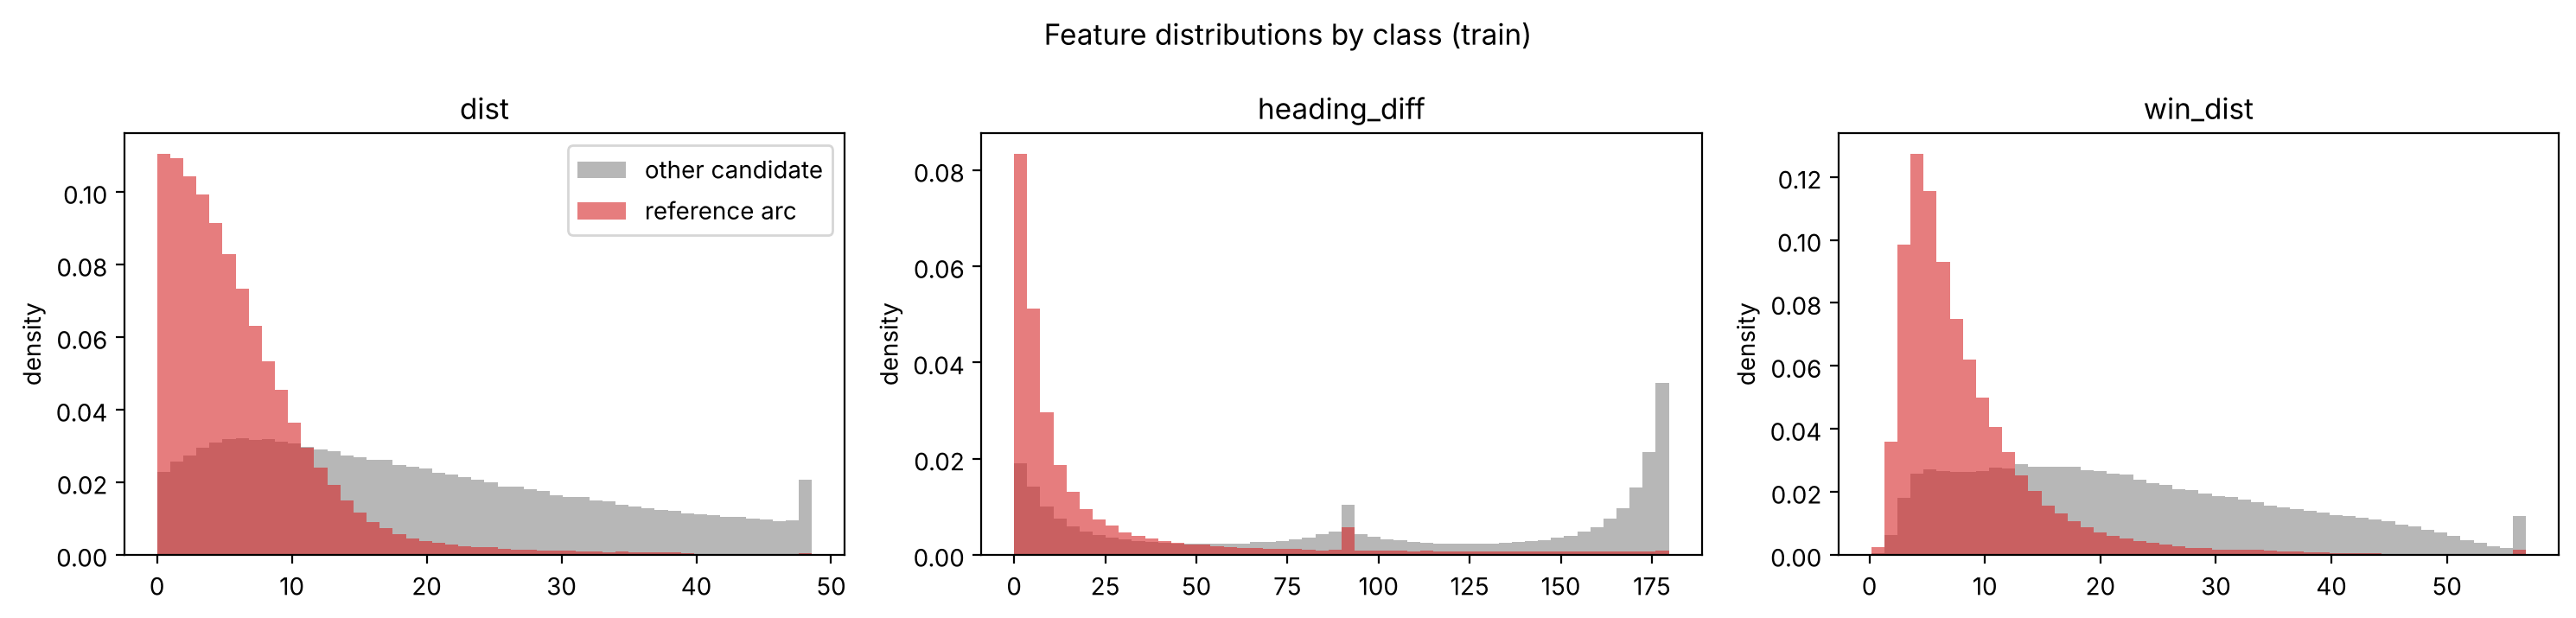

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, f in zip(ax, ["dist", "heading_diff", "win_dist"]):
    for lab, c in [(0, "#888"), (1, "#d62728")]:
        a.hist(tr.loc[tr.label == lab, f].clip(upper=tr[f].quantile(.99)), bins=50, alpha=.6, density=True,
               color=c, label="reference arc" if lab else "other candidate")
    a.set(title=f, ylabel="density")
ax[0].legend(); fig.suptitle("Feature distributions by class (train)"); fig.tight_layout(); nb.show()